# Cross-model distillation: student-hyperparameter exploration — results

Documents the July 21–22 2026 **student-HP exploration for cross-initialization (cross-model) distillation** of the dog trait: the teacher is the original `pythia-160m` (tseed1, `ex10-20_prefix_n100k` numbers), students are the PolyPythia re-seeds `data-seed1` / `weight-seed2`, and — unlike the cross-seed notebook, which fixes the student recipe — here the **student hyperparameters are the treatment**. Motivating question: cross-init transfer at the standard student recipe is weak (~0.02–0.15 test p(target) at ep20). Can a stronger student surface more of it?

**The experiment ladder** (each stage decided from the previous one's results; job lists in `run_logs/dog_crossdistill_studenthp_*_jobs.txt`, workers/launchers `run_logs/dog_crossdistill_studenthp_{worker.py,launcher.sh}`):

1. **Variant probe** (36 jobs, ep20): top-6 teacher configs by cross-init transfer × both cross bases × {lr 5e-4 · r8α32, lr 1e-4 · r16α64, lr 5e-4 · r16α64}.
2. **Dose check** (24 + 2 jobs): the two single-change variants at ep10; then lr 5e-4 at ep5 for the strongest config.
3. **Neighborhood grid** (33 jobs, focus cell `ep2_lr5e-4_r32a64 → data-seed1`): lr {1e-4, 2e-4, 3e-4} × LoRA {r8α32, r16α32, r8α64} × ep {5, 10, 20}, plus first seed replicates.
4. **Frontier at 3 seeds** (24 jobs, ep20): the surviving gentle region — {r8α16, r16α16, r16α32, r32α32, r32α64, r64α64} at lr 1e-4 and {r8α32, r16α32, r32α32} at lr 5e-5.
5. **ep40 dose rung** (6 jobs): winner (r16α32) and baseline (r8α32) × seeds 1–3.

**Headline findings** (verified below against the live artifacts): the student-lr cliff sits **between 1e-4 and 2e-4** and is absolute (every cell at lr ≥ 2e-4 scores < 0.005, most < 0.001, incl. 3-seed replication); LoRA **effective scale α/r is the same toxin** (scale 8 dies like 2× lr); the only direction that helps is **more capacity at gentler scale** ("slow and wide": r16α32 ep20 = 0.168 vs baseline mean 0.121); and **seed spread is large** (baseline ep20 seeds 0.039–0.171), so single-seed contrasts under ~±0.06 are noise.

> **Live notebook.** Sections self-filter to artifacts present on disk; frontier/ep40 cells appear as their sweeps drain. Single-seed cells carry no uncertainty; seed-replicated cells show per-seed points.

## Setup and per-seed artifact loader

Loads every student cell under the six top teacher lineages × both cross bases (plain `ex10-20_prefix_n100k` template): the seed-averaged `preference_summary.json` per cell **and** each `ftseed{N}/preference_eval.json` for per-seed test values — seed spread is a first-class object here. `runs` = one row per (cell, seed); `cells` = one row per cell with mean + seed tuple.

In [ ]:
from __future__ import annotations
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
STUDENTS_ROOT = OUTPUT_ROOT / "students"

ANIMAL, NBASE, TSEED, DATASET = "dog", "pythia-160m", 1, "ex10-20_prefix_n100k"
BASES = ["pythia-160m-data-seed1", "pythia-160m-weight-seed2"]
BASE_LABEL = {"pythia-160m-data-seed1": "data-seed1", "pythia-160m-weight-seed2": "weight-seed2"}
# The exploration's focus cell: the teacher config x student base with the strongest baseline transfer.
FOCUS_TEACHER, FOCUS_BASE = "ep2_lr5e-4_r32a64", "pythia-160m-data-seed1"
BASELINE_LR, BASELINE_LORA = 1e-4, (8, 32)   # the standard student recipe (Blank et al. port)

# Top-6 teacher tags by mean cross-init test at student ep20 (the variant-probe manifest, kept in run_logs).
TOP6_MANIFEST = ROOT / "run_logs/dog_crossdistill_top6_configs.json"
TOP6 = list(json.loads(TOP6_MANIFEST.read_text())["param_tags"]) if TOP6_MANIFEST.exists() else []
assert TOP6, "top-6 manifest missing"

STUDENT_TAG_RE = re.compile(r"^ep(?P<ep>\d+)_lr(?P<lr>[^_]+)_r(?P<r>\d+)a(?P<a>\d+)$")
set_plot_style(dpi=115, hide_spines=True)
print("output_root:", OUTPUT_ROOT); print("top-6 teachers:", TOP6)

In [2]:
def read(p): return json.loads(Path(p).read_text())

def load():
    run_rows, cell_rows = [], []
    for base in BASES:
        for tag in TOP6:
            lin = STUDENTS_ROOT / ANIMAL / base / f"from_{tag}_tseed{TSEED}_nbase-{NBASE}" / DATASET
            if not lin.exists(): continue
            for cd in sorted(lin.iterdir()):
                m = STUDENT_TAG_RE.fullmatch(cd.name)
                if not m or not (cd / "preference_summary.json").exists(): continue
                doc = read(cd / "preference_summary.json")
                mean_test = next((s["p_target_mean"] for s in doc.get("summaries", [])
                                  if s["prompt_set"] == "test"), None)
                seeds = {}
                for fd in sorted(cd.glob("ftseed*/preference_eval.json")):
                    n = int(re.search(r"ftseed(\d+)", str(fd))[1])
                    t = read(fd).get("sets", {}).get("test", {}).get("p_target")
                    if t is not None: seeds[n] = t
                meta = dict(teacher_tag=tag, base=base, student_tag=cd.name,
                            ep=int(m["ep"]), lr=float(m["lr"]), rank=int(m["r"]), alpha=int(m["a"]),
                            scale=int(m["a"]) / int(m["r"]))
                cell_rows.append({**meta, "mean_test": mean_test, "n_seeds": len(seeds),
                                  "seed_min": min(seeds.values(), default=np.nan),
                                  "seed_max": max(seeds.values(), default=np.nan)})
                for n, t in seeds.items(): run_rows.append({**meta, "seed": n, "test": t})
    return pd.DataFrame(cell_rows), pd.DataFrame(run_rows)

cells_df, runs = load()
assert len(cells_df), "no student cells found"
cells_df["is_baseline_hp"] = cells_df.lr.eq(BASELINE_LR) & cells_df["rank"].eq(BASELINE_LORA[0]) & cells_df.alpha.eq(BASELINE_LORA[1])
runs["is_baseline_hp"] = runs.lr.eq(BASELINE_LR) & runs["rank"].eq(BASELINE_LORA[0]) & runs.alpha.eq(BASELINE_LORA[1])
focus = cells_df[cells_df.teacher_tag.eq(FOCUS_TEACHER) & cells_df.base.eq(FOCUS_BASE)].copy()
focus_runs = runs[runs.teacher_tag.eq(FOCUS_TEACHER) & runs.base.eq(FOCUS_BASE)].copy()
print(f"{len(cells_df)} cells / {len(runs)} seed-runs across {cells_df.teacher_tag.nunique()} teachers x {cells_df.base.nunique()} bases")
print(f"focus cell ({FOCUS_TEACHER} -> {BASE_LABEL[FOCUS_BASE]}): {len(focus)} cells / {len(focus_runs)} seed-runs")

156 cells / 184 seed-runs across 6 teachers x 2 bases
focus cell (ep2_lr5e-4_r32a64 -> data-seed1): 45 cells / 73 seed-runs


## 1. Inventory

One row per (teacher, base): which student cells exist at which doses, and how many carry seed replicates. The focus lineage holds the deep grid; the other eleven (teacher × base) lineages carry the baseline ladder plus the stage-1/2 variants.

In [3]:
inv = cells_df.assign(hp=cells_df.student_tag.str.replace(r"^ep\d+_", "", regex=True))
cov = inv.pivot_table(index=["teacher_tag", "base"], columns="ep", values="student_tag", aggfunc="size").fillna(0).astype(int)
cov.index = [(t, BASE_LABEL[b]) for t, b in cov.index]
cov.columns = [f"ep{c}" for c in cov.columns]
display(cov.style.set_caption("Student cells per (teacher, base) x distillation epochs"))
seeded = cells_df[cells_df.n_seeds > 1][["teacher_tag", "base", "student_tag", "n_seeds", "mean_test", "seed_min", "seed_max"]]
seeded = seeded.assign(base=seeded.base.map(BASE_LABEL)).sort_values(["teacher_tag", "student_tag"])
display(seeded.style.format({c: "{:.3f}" for c in ["mean_test", "seed_min", "seed_max"]})
        .set_caption("Seed-replicated cells (n_seeds > 1)").hide(axis="index"))

,ep1,ep2,ep5,ep10,ep20,ep40
"('ep20_lr1e-4_r32a32', 'data-seed1')",1,1,1,3,4,0
"('ep20_lr1e-4_r32a32', 'weight-seed2')",1,1,1,3,4,0
"('ep20_lr1e-4_r8a32', 'data-seed1')",1,1,1,3,4,0
"('ep20_lr1e-4_r8a32', 'weight-seed2')",1,1,1,3,4,0
"('ep20_lr2e-4_r8a8', 'data-seed1')",1,1,1,3,4,0
"('ep20_lr2e-4_r8a8', 'weight-seed2')",1,1,1,3,4,0
"('ep2_lr5e-4_r16a64', 'data-seed1')",1,1,1,3,4,0
"('ep2_lr5e-4_r16a64', 'weight-seed2')",1,1,1,3,4,0
"('ep2_lr5e-4_r32a64', 'data-seed1')",1,1,10,11,20,2
"('ep2_lr5e-4_r32a64', 'weight-seed2')",1,1,2,3,4,0


teacher_tag,base,student_tag,n_seeds,mean_test,seed_min,seed_max
ep2_lr5e-4_r32a64,data-seed1,ep10_lr1e-4_r8a32,3,0.057,0.032,0.072
ep2_lr5e-4_r32a64,data-seed1,ep20_lr1e-4_r16a16,3,0.067,0.057,0.081
ep2_lr5e-4_r32a64,data-seed1,ep20_lr1e-4_r16a32,3,0.099,0.047,0.168
ep2_lr5e-4_r32a64,data-seed1,ep20_lr1e-4_r32a32,3,0.107,0.048,0.178
ep2_lr5e-4_r32a64,data-seed1,ep20_lr1e-4_r32a64,3,0.046,0.002,0.105
ep2_lr5e-4_r32a64,data-seed1,ep20_lr1e-4_r64a64,3,0.083,0.041,0.150
ep2_lr5e-4_r32a64,data-seed1,ep20_lr1e-4_r8a16,3,0.075,0.052,0.116
ep2_lr5e-4_r32a64,data-seed1,ep20_lr1e-4_r8a32,3,0.121,0.039,0.171
ep2_lr5e-4_r32a64,data-seed1,ep20_lr2e-4_r8a32,3,0.000,0.000,0.000
ep2_lr5e-4_r32a64,data-seed1,ep20_lr5e-5_r16a32,3,0.077,0.059,0.093


## 2. Stage 1–2: the three "stronger student" variants collapse

Across the top-6 teachers × both bases, each panel pairs the baseline recipe (x) against one variant (y) at the same dose. Everything below the identity line lost transfer. lr 5e-4 is a flat wall at ≈0 (< 0.005 in every cell) — at ep20, ep10 **and** ep5 — while r16α64 (same lr) scatters at-or-below baseline. The "more aggressive student" hypothesis fails uniformly.

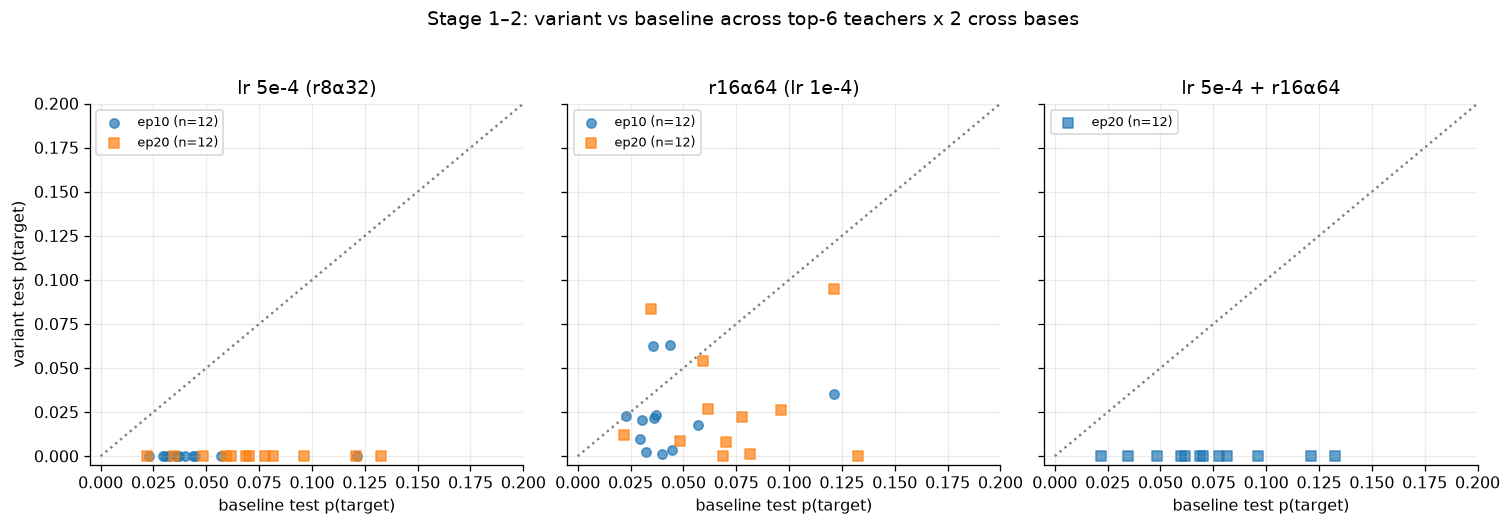

lr 5e-4 (r8α32)        cells= 26  <0.001:  26  >0.005:   0
r16α64 (lr 1e-4)       cells= 24  <0.001:   2  >0.005:  18
lr 5e-4 + r16α64       cells= 12  <0.001:  12  >0.005:   0


In [4]:
VARIANTS = [(5e-4, 8, 32, "lr 5e-4 (r8α32)"), (1e-4, 16, 64, "r16α64 (lr 1e-4)"), (5e-4, 16, 64, "lr 5e-4 + r16α64")]
DOSES2 = [10, 20]
fig, axs = plt.subplots(1, 3, figsize=(13.2, 4.4), sharey=True)
mark = {10: "o", 20: "s"}
for ax, (lr, r, a, lab) in zip(axs, VARIANTS):
    for ep in DOSES2:
        b = cells_df[cells_df.is_baseline_hp & cells_df.ep.eq(ep)].set_index(["teacher_tag", "base"]).mean_test
        v = cells_df[cells_df.lr.eq(lr) & cells_df["rank"].eq(r) & cells_df.alpha.eq(a) & cells_df.ep.eq(ep)] \
            .set_index(["teacher_tag", "base"]).mean_test
        j = b.index.intersection(v.index)
        if not len(j): continue
        ax.scatter(b.loc[j], v.loc[j], s=34, alpha=.7, marker=mark[ep], label=f"ep{ep} (n={len(j)})")
    ax.plot([0, .2], [0, .2], color=".5", ls=":")
    ax.set(title=lab, xlabel="baseline test p(target)", xlim=(-.005, .2), ylim=(-.005, .2))
    ax.legend(fontsize=8)
axs[0].set_ylabel("variant test p(target)")
fig.suptitle("Stage 1–2: variant vs baseline across top-6 teachers x 2 cross bases", y=1.03)
plt.tight_layout(); plt.show()
for lr, r, a, lab in VARIANTS:
    sub = cells_df[cells_df.lr.eq(lr) & cells_df["rank"].eq(r) & cells_df.alpha.eq(a)]
    print(f"{lab:22} cells={len(sub):3d}  <0.001: {int((sub.mean_test < 0.001).sum()):3d}  >0.005: {int((sub.mean_test > 0.005).sum()):3d}")

## 3. The learning-rate cliff (focus cell)

Transfer vs student lr at each dose, log-x, per-seed points overlaid. The cliff sits **between 1e-4 and 2e-4**: 2e-4 is already ≈0 (< 0.005) at every dose and LoRA (three seeds at ep20 confirm the collapse is not noise), and nothing recovers at shorter doses — the rate itself, not the accumulated dose, destroys the transfer channel. The 5e-5 probe (frontier sweep) shows whether *gentler*-than-standard helps at matched epochs.

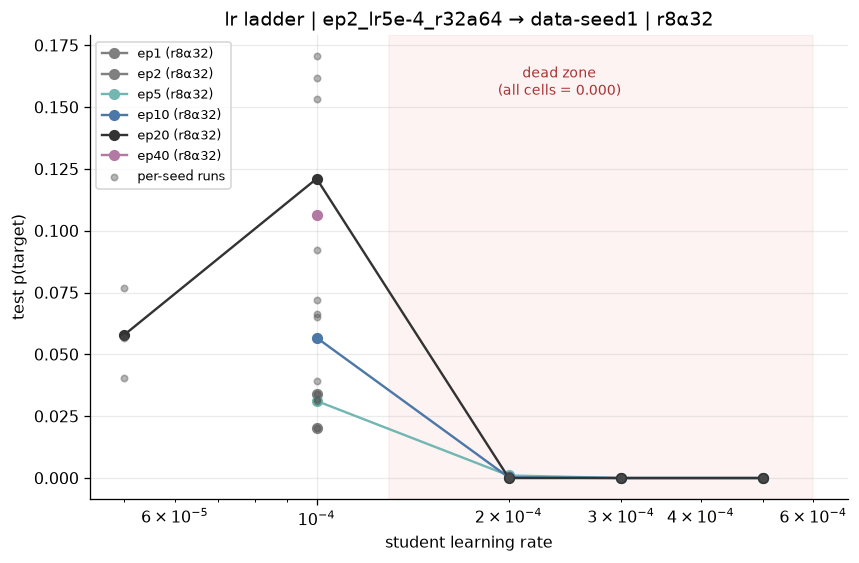

cells at lr>=2e-4: 22, all <0.005: True, <0.001: 21 (incl. 24 seed-runs)


In [5]:
lad = focus[focus["rank"].eq(8) & focus.alpha.eq(32) | focus.lr.ge(2e-4) | focus.lr.le(5e-5)]
fig, ax = plt.subplots(figsize=(7.6, 5))
col = {5: "#72b7b2", 10: "#4c78a8", 20: "#333333", 40: "#b279a2"}
for ep in sorted(lad.ep.unique()):
    g = lad[lad.ep.eq(ep) & lad["rank"].eq(8) & lad.alpha.eq(32)].sort_values("lr")
    if not len(g): continue
    ax.plot(g.lr, g.mean_test, marker="o", color=col.get(ep, "gray"), label=f"ep{ep} (r8α32)")
fr = focus_runs[focus_runs["rank"].eq(8) & focus_runs.alpha.eq(32)]
ax.scatter(fr.lr, fr.test, s=16, alpha=.4, color=".3", zorder=3, label="per-seed runs")
ax.axvspan(1.3e-4, 6e-4, color="#e45756", alpha=.07)
ax.text(2.4e-4, .155, "dead zone\n(all cells = 0.000)", color="#a33", fontsize=9, ha="center")
ax.set(xscale="log", xlabel="student learning rate", ylabel="test p(target)",
       title=f"lr ladder | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | r8α32")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
dead = focus[focus.lr.ge(2e-4)]
print(f"cells at lr>=2e-4: {len(dead)}, all <0.005: {bool((dead.mean_test < 0.005).all())}, "
      f"<0.001: {int((dead.mean_test < 0.001).sum())} (incl. {int(dead.n_seeds.sum())} seed-runs)")

## 4. LoRA scale vs capacity (focus cell, lr 1e-4)

Each point is one (rank, α) cell at lr 1e-4, x = effective scale α/r, size = rank, one panel per dose. Scale is the second aggression knob and behaves like lr: scale 8 (r8α64) dies by ep20 exactly like 2× lr does. Within the surviving region (scale ≤ 4), **capacity helps at gentle scale** — r16α32 (scale 2) posted the best single-seed cell at ep20 (0.168, but mean 0.099 over 3 seeds — within noise of baseline) — while the same capacity at scale 4 (r16α64) sits below baseline. Frontier cells (r16α16, r32α32, r32α64, r64α64, r8α16) slot into these panels as their sweeps land.

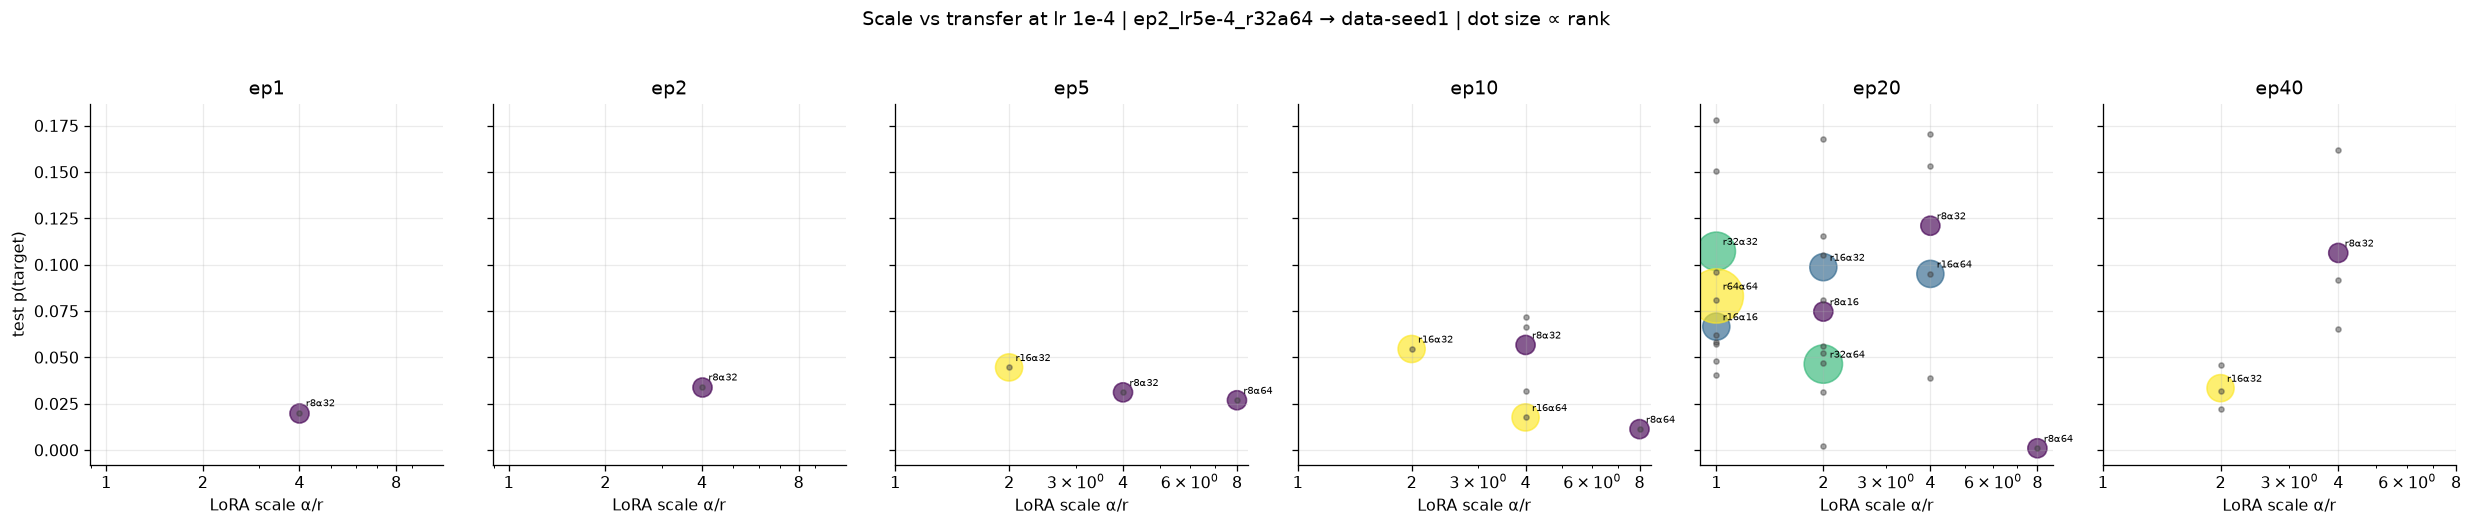

In [6]:
g1 = focus[focus.lr.eq(1e-4)]
eps = sorted(g1.ep.unique())
fig, axs = plt.subplots(1, len(eps), figsize=(3.6 * len(eps), 4.4), sharey=True, squeeze=False)
for ax, ep in zip(axs[0], eps):
    sub = g1[g1.ep.eq(ep)]
    sc = ax.scatter(sub.scale, sub.mean_test, s=18 * sub["rank"], alpha=.65,
                    c=np.log2(sub["rank"]), cmap="viridis")
    rr = focus_runs[focus_runs.lr.eq(1e-4) & focus_runs.ep.eq(ep)]
    ax.scatter(rr.scale, rr.test, s=10, color=".25", alpha=.45, zorder=3)
    for _, row in sub.iterrows():
        ax.annotate(f"r{row['rank']}α{row.alpha}", (row.scale, row.mean_test),
                    textcoords="offset points", xytext=(4, 4), fontsize=6.5)
    ax.set(xscale="log", title=f"ep{ep}", xlabel="LoRA scale α/r", xticks=[1, 2, 4, 8],
           xticklabels=["1", "2", "4", "8"])
axs[0][0].set_ylabel("test p(target)")
fig.suptitle(f"Scale vs transfer at lr 1e-4 | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | dot size ∝ rank", y=1.03)
plt.tight_layout(); plt.show()

## 5. Dose response of the surviving recipes

Held-out transfer vs student epochs for every lr-1e-4 (rank, α) recipe with any signal, per-seed points overlaid. The baseline ladder (ep1–ep20 from the main sweeps) plus the exploration's ep5/10/20 grid and the ep40 rung. Dose is the one axis that has consistently paid — the question ep40 answers is whether the dose curves are still rising or saturating.

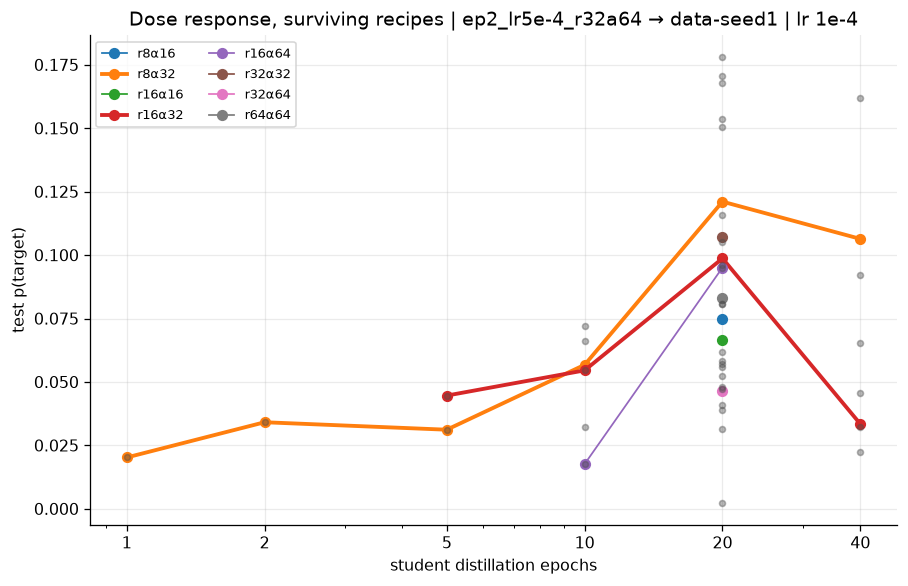

In [7]:
g = focus[focus.lr.eq(1e-4) & focus.scale.le(4)]
fig, ax = plt.subplots(figsize=(8, 5.2))
for (r, a), sub in g.groupby(["rank", "alpha"]):
    sub = sub.sort_values("ep")
    if sub.mean_test.max() < .005 and len(sub) < 2: continue
    lw = 2.4 if (r, a) in [(8, 32), (16, 32)] else 1.1
    ax.plot(sub.ep, sub.mean_test, marker="o", lw=lw, label=f"r{r}α{a}")
rr = focus_runs[focus_runs.lr.eq(1e-4) & focus_runs.scale.le(4)]
ax.scatter(rr.ep, rr.test, s=14, color=".3", alpha=.4, zorder=3)
ax.set(xlabel="student distillation epochs", ylabel="test p(target)", xscale="log",
       xticks=[1, 2, 5, 10, 20, 40], xticklabels=[1, 2, 5, 10, 20, 40],
       title=f"Dose response, surviving recipes | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | lr 1e-4")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

## 6. Seed noise vs signal

Per-seed spread for every replicated cell. The pooled within-cell seed SD sets the resolution limit for single-seed comparisons — with the baseline ep20 cell spanning 0.039–0.171, cell contrasts below ~±0.06 are not interpretable without replication. The zeros are different: lr 2e-4 replicates at < 0.001 on every seed, so the cliff is signal, not noise.

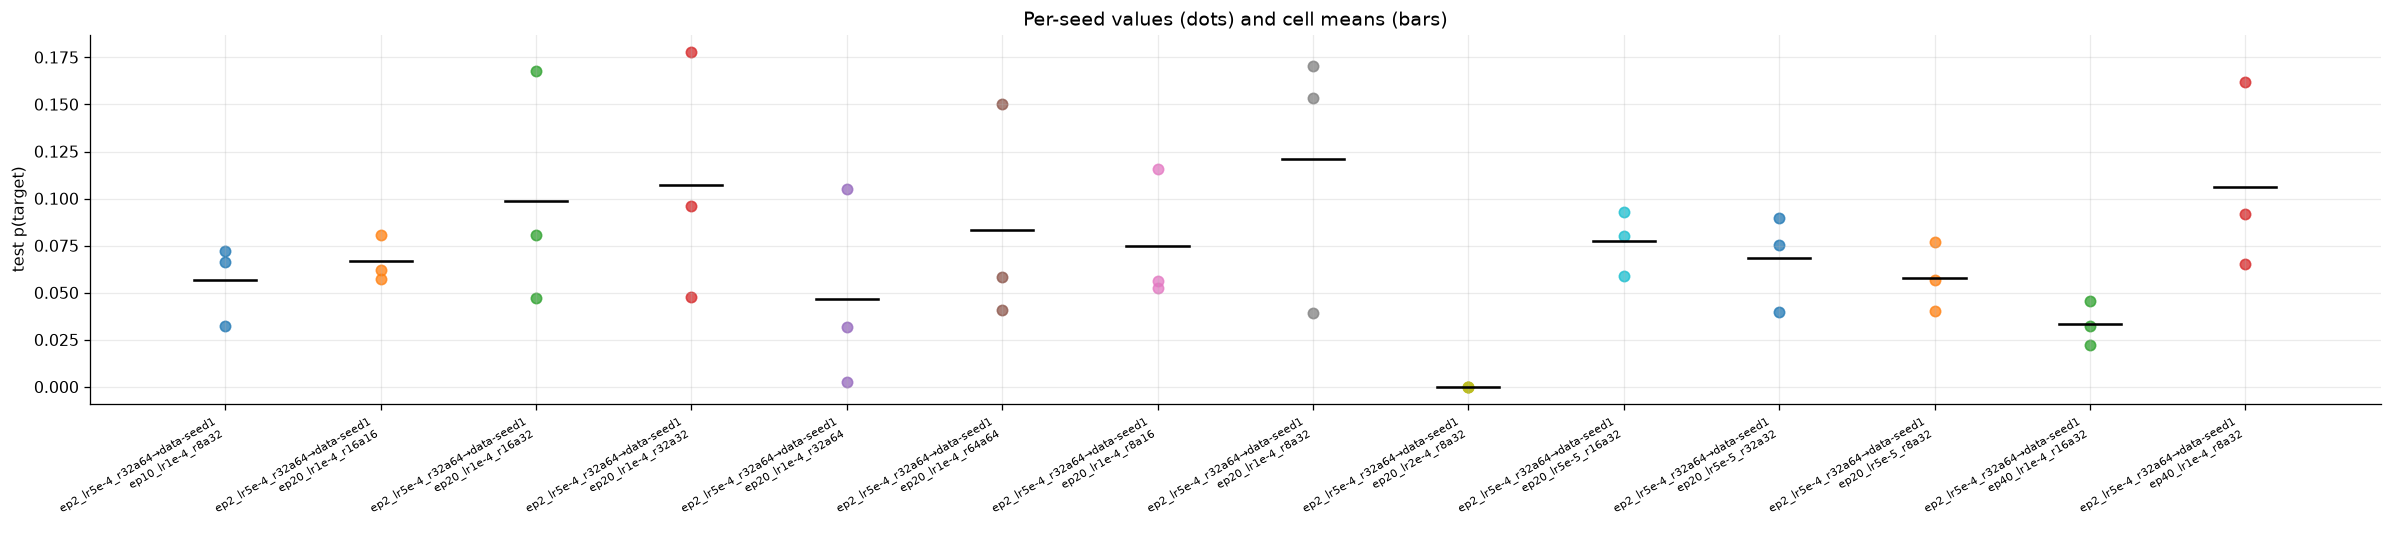

pooled within-cell seed SD (non-zero cells): 0.044  (collapsed cells contribute ~0 SD)


In [8]:
rep = runs.merge(cells_df[cells_df.n_seeds > 1][["teacher_tag", "base", "student_tag"]].drop_duplicates())
if len(rep):
    labels = [f"{t}→{BASE_LABEL[b]}\n{s}" for t, b, s in
              rep[["teacher_tag", "base", "student_tag"]].drop_duplicates().itertuples(index=False)]
    keys = list(rep[["teacher_tag", "base", "student_tag"]].drop_duplicates().itertuples(index=False))
    fig, ax = plt.subplots(figsize=(1.35 * len(keys) + 2, 4.8))
    for i, k in enumerate(keys):
        sub = rep[rep.teacher_tag.eq(k[0]) & rep.base.eq(k[1]) & rep.student_tag.eq(k[2])]
        ax.scatter([i] * len(sub), sub.test, s=42, alpha=.75)
        ax.plot([i - .2, i + .2], [sub.test.mean()] * 2, color="black", lw=1.6)
    ax.set(xticks=range(len(keys)), ylabel="test p(target)", title="Per-seed values (dots) and cell means (bars)")
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=7)
    plt.tight_layout(); plt.show()
    sd = rep.groupby(["teacher_tag", "base", "student_tag"]).test.std()
    nz = sd[rep.groupby(["teacher_tag", "base", "student_tag"]).test.mean() > .005]
    print(f"pooled within-cell seed SD (non-zero cells): {np.sqrt((nz**2).mean()):.3f}  "
          f"(collapsed cells contribute ~0 SD)")
else:
    print("no seed-replicated cells on disk yet")

## 7. The whole exploration in one grid

The house-style 2D view from the teacher/steerability notebooks (`analysis.plots.facet_heatmaps`), but the axes are **student** hyperparameters: rows = distillation epochs, columns = LoRA rank/α, one panel per student lr; the teacher is fixed at the focus config `ep2_lr5e-4_r32a64` (tseed1) → `data-seed1`. Cell value = mean test p(target) over ft seeds, and the `n{K}` suffix in every cell states exactly how many seeds that mean averages — `n1` cells are single runs with no uncertainty, `n3` cells are 3-seed means (the frontier, the ep40 rung, and key cliff/baseline cells); the printout below the figure lists every seed-averaged cell with its seed range. Blank cells were never run; red box = the standard recipe at ep20 (the baseline every contrast is judged against). Colour scale is capped at 0.2 — cross-init transfer tops out ~0.17, so the teacher notebooks' 0–1 scale would render everything dark.

Reading left→right as increasing lr: the three panels at lr ≥ 2e-4 are uniformly dead (< 0.005, incl. the 3-seed ep20 replicate) — the cliff from §3 as territory rather than a curve. Every live cell sits in the lr 1e-4 panel, which contains its own within-panel copy of the cliff along the column axis (scale 8 = r8/α64 dies by ep20 exactly like 2× lr). The 5e-5 panel shows gentler-than-standard pays no premium at matched dose.

top cells: ep20_lr1e-4_r8a32=0.121 (n3); ep20_lr1e-4_r32a32=0.107 (n3); ep40_lr1e-4_r8a32=0.106 (n3)
seed coverage: 31 cells at n1, 14 cells at n3
seed-averaged cells (n>1):
  ep20_lr5e-5_r16a32     n3  mean=0.077  seeds [0.059, 0.093]
  ep20_lr5e-5_r32a32     n3  mean=0.068  seeds [0.040, 0.090]
  ep20_lr5e-5_r8a32      n3  mean=0.058  seeds [0.040, 0.077]
  ep10_lr1e-4_r8a32      n3  mean=0.057  seeds [0.032, 0.072]
  ep20_lr1e-4_r16a16     n3  mean=0.067  seeds [0.057, 0.081]
  ep20_lr1e-4_r16a32     n3  mean=0.099  seeds [0.047, 0.168]
  ep20_lr1e-4_r32a32     n3  mean=0.107  seeds [0.048, 0.178]
  ep20_lr1e-4_r32a64     n3  mean=0.046  seeds [0.002, 0.105]
  ep20_lr1e-4_r64a64     n3  mean=0.083  seeds [0.041, 0.150]
  ep20_lr1e-4_r8a16      n3  mean=0.075  seeds [0.052, 0.116]
  ep20_lr1e-4_r8a32      n3  mean=0.121  seeds [0.039, 0.171]
  ep40_lr1e-4_r16a32     n3  mean=0.033  seeds [0.022, 0.046]
  ep40_lr1e-4_r8a32      n3  mean=0.106  seeds [0.065, 0.162]
  ep20_lr2e-4_r8a32 

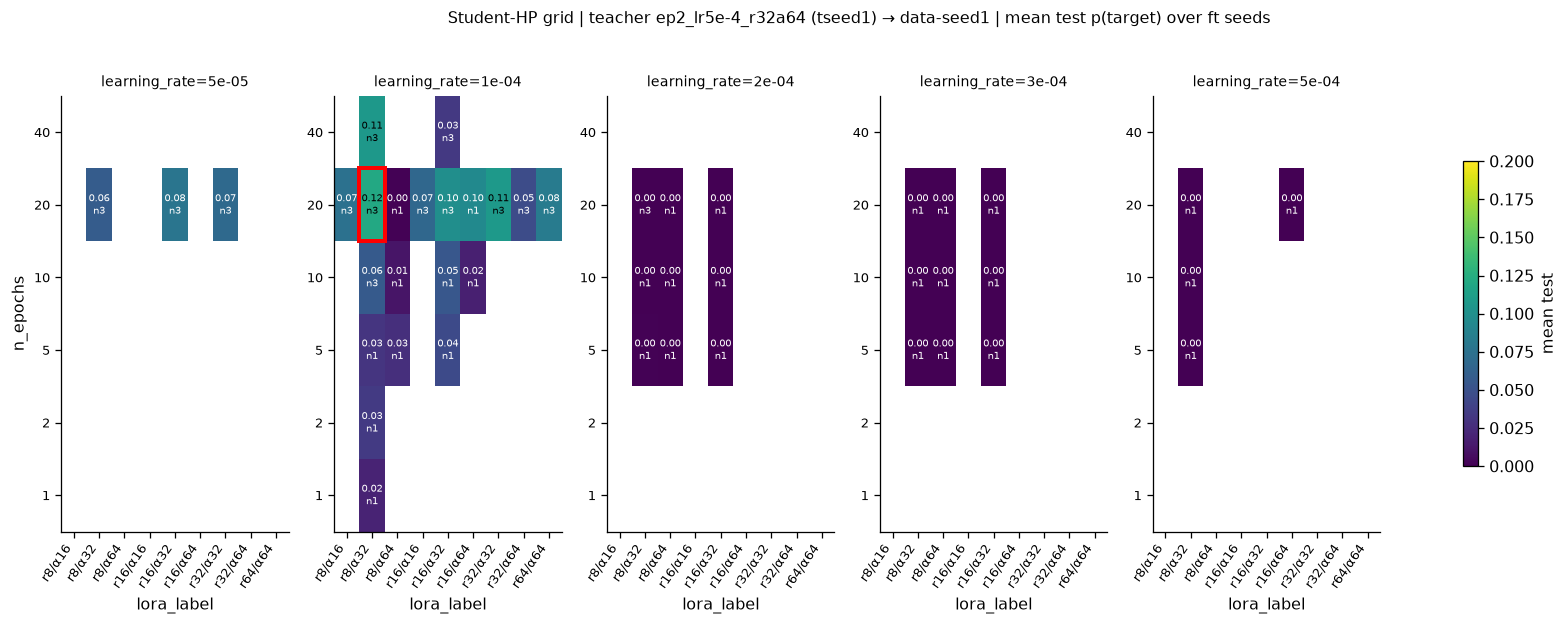

In [9]:
from subliminal_learning.analysis import frames, plots as aplots

hp = frames.add_lora_label(focus_runs.rename(
    columns={"ep": "n_epochs", "lr": "learning_rate", "rank": "lora_r", "alpha": "lora_alpha"}))
_ = aplots.facet_heatmaps(
    hp, "n_epochs", "lora_label", "learning_rate", "test",
    show_n=True, vmin=0.0, vmax=0.2,
    highlight=(20, f"r{BASELINE_LORA[0]}/α{BASELINE_LORA[1]}", BASELINE_LR),
    title=(f"Student-HP grid | teacher {FOCUS_TEACHER} (tseed{TSEED}) → {BASE_LABEL[FOCUS_BASE]} | "
           "mean test p(target) over ft seeds"),
)
top = focus.sort_values("mean_test", ascending=False).head(3)
print("top cells:", "; ".join(f"{t.student_tag}={t.mean_test:.3f} (n{t.n_seeds})" for t in top.itertuples()))
cov = focus.groupby("n_seeds").size()
print("seed coverage:", ", ".join(f"{v} cells at n{k}" for k, v in cov.items()))
rep = focus[focus.n_seeds > 1].sort_values(["lr", "student_tag"])
print("seed-averaged cells (n>1):")
for t in rep.itertuples():
    print(f"  {t.student_tag:22} n{t.n_seeds}  mean={t.mean_test:.3f}  seeds [{t.seed_min:.3f}, {t.seed_max:.3f}]")

### Interpretation checklist

- Every number here is **cross-initialization** transfer into a re-seeded PolyPythia — the same-init reference lives in the cross-seed notebook, at ~2–6× these levels.
- The two aggression knobs (lr, LoRA scale α/r) share one cliff: effective step size. lr ≥ 2e-4 or scale ≥ 8 ⇒ < 0.005 everywhere (most cells < 0.001), replicated. Do not re-test the dead zone.
- The surviving region is a plateau: lr 1e-4, scale ≤ 4, any rank tried — all within seed noise of the standard recipe. The seed-1 r16α32 "win" (0.168) did not replicate (mean 0.099 vs baseline 0.121). No tested variant beats baseline.
- Seed spread on live cells is large (±0.06); only replicated contrasts count. The exploration deliberately puts 3 seeds on the frontier and on the ep40 rung.
- Everything is one teacher config × one student base beyond stage 1–2 — before believing a recipe, replicate it on `weight-seed2` and on the #2/#3 teacher configs (the natural next stage).
- `off_topic` was never scored for these students; specificity claims need that backfill first.